In [1]:
import numpy             as np
import matplotlib.pyplot as plt
import seaborn           as sns
import multiprocess      as mp
import pandas            as pd

from libraries                         import utils
from pymatgen.analysis.phase_diagram   import PhaseDiagram
from pymatgen.entries.computed_entries import ComputedEntry
from os                                import path
from sklearn                           import model_selection
from sklearn.ensemble                  import RandomForestRegressor
from sklearn.neural_network            import MLPRegressor
from sklearn.model_selection           import ShuffleSplit

sns.set_theme()

Defining general output properties

In [2]:
linewidth      = 0.5
footnotesize   = 8
s_footnotesize = 10*0.8
eps_dpi        = 100
png_dpi        = 400
output_folder  = 'output/ternary_chalcohalides'
input_folder   = 'input/ternary_chalcohalides'

# Iterations might be run from here

In [3]:
miller_index = '010'

In [4]:
vbm     = np.loadtxt(f'{input_folder}/results_vbm_{miller_index}.txt')
bandgap = np.loadtxt(f'{input_folder}/results_band_gap.txt')

In [5]:
# Convert the array to a Pandas DataFrame
vbmd = pd.DataFrame(vbm, columns=["x", "y", "z", "VBM"])
vbmd.set_index(["x", "y", "z"], inplace=True)

bandgapd = pd.DataFrame(bandgap, columns=["x", "y", "z", "bandgap"])
bandgapd.set_index(["x", "y", "z"], inplace=True)

# Combine the DataFrames, aligning by index
data = pd.concat([vbmd, bandgapd], axis=1)

data['CBM'] = data['VBM'] + data['bandgap']
data

VBM   bandgap       CBM
x   y   z                                 
0.0 0.0 0.00 -5.883715  1.524687 -4.359028
        0.05 -5.884668  1.529355 -4.355313
        0.10 -5.885797  1.532872 -4.352925
        0.15 -5.886994  1.536684 -4.350310
        0.20 -5.889283  1.542081 -4.347201
...                ...       ...       ...
1.0 1.0 0.80 -6.228421  1.596269 -4.632152
        0.85 -6.209499  1.575322 -4.634176
        0.90 -6.189808  1.553251 -4.636557
        0.95 -6.170496  1.529336 -4.641160
        1.00 -6.150436  1.505291 -4.645145

[1819 rows x 3 columns]

In [6]:
(data['VBM'] - -5.67).abs().idxmin()

(np.float64(0.0), np.float64(0.0), np.float64(1.0))

In [7]:
(data['CBM'] - 4.44).abs().idxmin()

(np.float64(0.0), np.float64(1.0), np.float64(0.0))

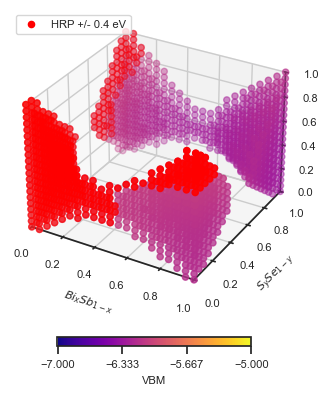

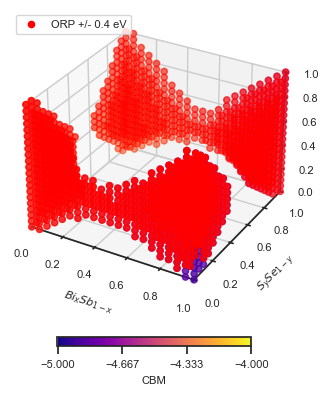

In [8]:
valid_xyz = np.array(data.index.to_frame(index=False).values)
for target in ['VBM', 'CBM']:
    threshold = 0.4
    if target == 'VBM':
        # Hydrogen reduction potential
        name = f'HRP +/- {threshold:.1f} eV'
        oxidation_potential = -5.67

    elif target == 'CBM':
        # Oxygen reduction potential
        name = f'ORP +/- {threshold:.1f} eV'
        oxidation_potential = -4.44

    # Get the solid solution with valence and conduction band edges closest to the oxygen/hydrogen reduction potential
    min_arg = (data[target] - (oxidation_potential)).abs().idxmin()
    highlight_mask = data[target].between(oxidation_potential - threshold, oxidation_potential + threshold)

    valid_pred = data[target].values
    bar_name = target
    sns.set_theme(style='white')

    fig = plt.figure(figsize=(5, 5))
    ax  = plt.axes(projection='3d')

    # Setting minimum and maximum values for the colorbar
    vmin = np.floor(np.min(valid_pred))
    vmax = np.ceil(np.max(valid_pred))

    # Plotting valid points
    sc = ax.scatter(valid_xyz[:, 0],
                    valid_xyz[:, 1],
                    valid_xyz[:, 2],
                    c=valid_pred,
                    vmin=vmin, vmax=vmax,
                    marker='o', cmap='plasma')

    # Highlighting points within the specified range
    highlight_xyz = valid_xyz[highlight_mask]
    ax.scatter(highlight_xyz[:, 0],
               highlight_xyz[:, 1],
               highlight_xyz[:, 2],
               c='red', marker='o', label=name)

    # Bar
    cbar = fig.colorbar(sc, orientation='horizontal', location='bottom',
                        pad=0.1, shrink=0.5, ticks=np.linspace(vmin, vmax, 4))

    # Defining bar
    cbar.ax.tick_params(labelsize=footnotesize)
    cbar.set_label(bar_name, fontsize=footnotesize)

    # Setting labels
    ax.set_xlabel(r'$Bi_x Sb_{1-x}$',  fontsize=footnotesize)
    ax.set_ylabel(r'$S_y Se_{1-y}$',  fontsize=footnotesize)
    ax.set_zlabel(r'$I_z Br_{1-z}$',  fontsize=footnotesize)

    # Setting number to scale
    ax.tick_params(axis='x', labelsize=footnotesize)
    ax.tick_params(axis='y', labelsize=footnotesize)
    ax.tick_params(axis='z', labelsize=footnotesize)

    # Setting limits
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_zlim(0, 1)

    # Adding legend
    ax.legend(loc='upper left', fontsize=footnotesize)

    # Saving the figure
    plt.savefig(f'{output_folder}/valid_region_{target}_{miller_index}.png', dpi=300)
    plt.show()